# Environmental Sound Classification (ESC-50)
**Deep Learning Module Project – Cohort 19**
**Name:** _your name_  **Date:** _date_

In this project I classify 5-second sound clips into 50 classes (dog, rain, siren, ...) in three ways:
1. a small CNN built **from scratch** (Task 1),
2. the **same CNN improved** with training techniques (Task 2),
3. a **pretrained Transformer** (AST) fine-tuned on the same data (Task 3).

Then I compare everything on a test set that I only use at the end.

**Contents:** 1 Problem · 2 Data · 3 Task 1 · 4 Task 2 · 5 Task 3 · 6 Evaluation · 7 Limitations · 8 Reflection

> Run on Google Colab with a GPU (Runtime → Change runtime type → T4 GPU), then *Run all*.

In [ ]:
%pip install -q "transformers>=4.41,<5" "datasets>=2.19,<4.0" accelerate librosa soundfile scikit-learn seaborn

In [ ]:
import os, re, glob, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from datasets import load_dataset, Audio
from transformers import ASTFeatureExtractor, ASTForAudioClassification, TrainingArguments, Trainer

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from IPython.display import Audio as PlayAudio, display

# TensorFlow and PyTorch share the GPU, so TensorFlow must not grab all the memory
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

# fixed random seed so my results can be repeated
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); keras.utils.set_random_seed(SEED)

SR = 16000              # sample rate I use for all audio
CLIP_LEN = SR * 5       # every clip is 5 seconds
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch device:", device, "| TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

PyTorch device: cuda | TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Problem Definition

- **What I predict:** the class of a 5-second audio clip (one of 50 environmental sounds). **Input:** audio, turned into a spectrogram.
- **Why it matters:** a cheap microphone can detect dangerous or important sounds without a camera: glass breaking, siren, crying baby, fireworks, car horn. It can help hearing-impaired people (visual alerts), home safety systems, and noise monitoring in cities.
- **Output:** 50 classes (softmax).
- **What is "good enough"** (decided before looking at test results):
  - test **macro-F1 ≥ 0.90**, and
  - **recall ≥ 0.875** (at least 7 of 8 test clips) for 6 safety classes: `siren`, `glass_breaking`, `crying_baby`, `fireworks`, `car_horn`, `chainsaw`.

## 2. Dataset and EDA

- **Dataset:** ESC-50 from Hugging Face (`ashraq/esc50`). 2,000 clips, 50 classes, 40 clips per class.
- **Licence:** CC BY-NC 3.0 (non-commercial use). Clips come from Freesound.

In [ ]:
raw = load_dataset("ashraq/esc50", split="train")
raw = raw.cast_column("audio", Audio(sampling_rate=SR))   # resample to 16 kHz
meta = raw.remove_columns("audio").to_pandas()            # table with filename, fold, target, category ...
meta.head()

Repo card metadata block was not found. Setting CardData to empty.


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [ ]:
# class names in order of their label number (0..49)
class_names = meta.drop_duplicates("target").sort_values("target")["category"].tolist()
y = meta["target"].values
print(len(class_names), "classes:", class_names[:6], "...")
print("clips:", len(meta))

50 classes: ['dog', 'rooster', 'pig', 'cow', 'frog', 'cat'] ...
clips: 2000


### Class distribution

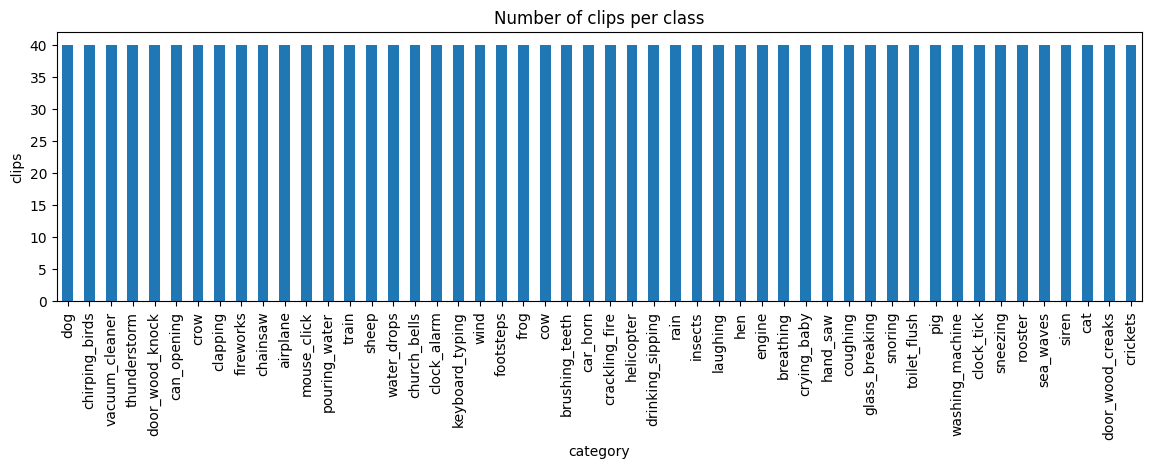

min = 40  max = 40 -> the classes are perfectly balanced


In [ ]:
counts = meta["category"].value_counts()
plt.figure(figsize=(14, 3.5))
counts.plot.bar()
plt.title("Number of clips per class"); plt.ylabel("clips")
plt.show()
print("min =", counts.min(), " max =", counts.max(), "-> the classes are perfectly balanced")

### Load the audio into one array

In [ ]:
waves = []
for i in range(len(raw)):
    x = np.array(raw[i]["audio"]["array"], dtype=np.float32)
    x = np.pad(x, (0, max(0, CLIP_LEN - len(x))))[:CLIP_LEN]   # make every clip exactly 5 s
    waves.append(x)
waves = np.array(waves)
print("waves shape:", waves.shape)

# many clips are short sounds followed by silence - let me check how much
silence = (np.abs(waves) < 1e-5).mean(axis=1)
print("average share of silence in a clip:", round(silence.mean() * 100, 1), "%")

waves shape: (2000, 80000)
average share of silence in a clip: 10.5 %


### Preprocessing and sample spectrograms
I convert each clip into a **log-mel spectrogram** (64 mel bands × 251 time steps). It is like a grayscale image of the sound, so I can use a CNN on it.

spectrograms: (2000, 64, 251)


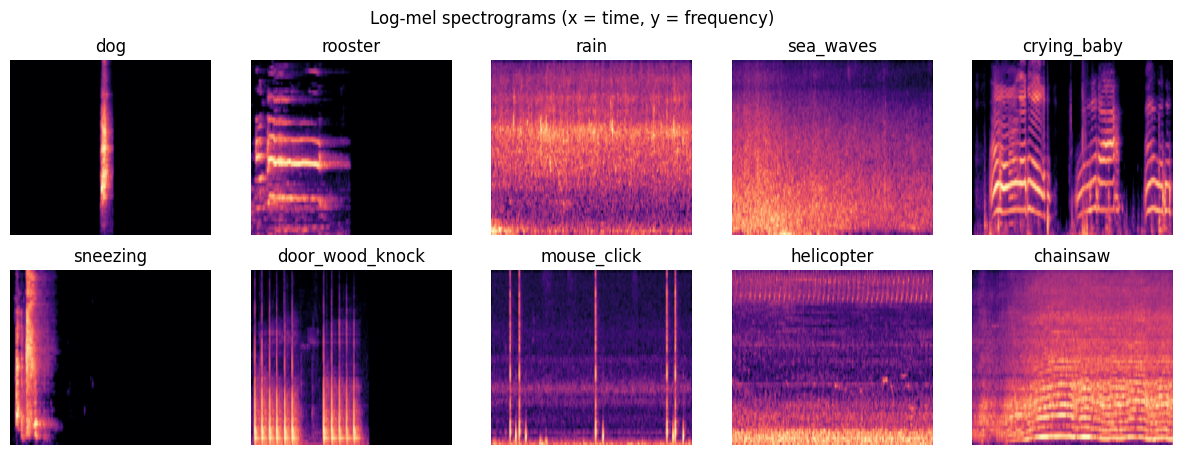

Listen to: dog


In [ ]:
def to_mel(x):
    mel = librosa.feature.melspectrogram(y=x, sr=SR, n_fft=1024, hop_length=320, n_mels=64)
    return librosa.power_to_db(mel, ref=np.max)        # shape (64, 251)

X_all = np.array([to_mel(x) for x in waves])           # (2000, 64, 251)
print("spectrograms:", X_all.shape)

# one example from 10 different classes
fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for ax, c in zip(axes.ravel(), [0, 1, 10, 11, 20, 21, 30, 31, 40, 41]):
    i = np.where(y == c)[0][0]
    ax.imshow(X_all[i], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(class_names[c]); ax.axis("off")
plt.suptitle("Log-mel spectrograms (x = time, y = frequency)")
plt.show()

i = np.where(y == 0)[0][0]
print("Listen to:", class_names[0])
display(PlayAudio(waves[i], rate=SR))

### Train / validation / test split
ESC-50 comes with 5 **folds**. Some clips are cut from the same long recording, and the dataset makes sure that those clips stay in the same fold. If I split randomly, almost-identical clips could end up in both train and test, and my scores would look better than they really are. So I use the folds:

| Split | Folds | Clips |
|---|---|---|
| Train | 1, 2, 3 | 1200 |
| Validation | 4 | 400 |
| **Test** | 5 | 400 (**used only once, in Section 6**) |

Every class has the same number of clips in each fold, so the split is stratified.

In [ ]:
fold = meta["fold"].values
train_idx = np.where(fold <= 3)[0]
val_idx   = np.where(fold == 4)[0]
test_idx  = np.where(fold == 5)[0]
print("train:", len(train_idx), "| val:", len(val_idx), "| test:", len(test_idx))

# check: no source recording appears in two splits (no leakage)
if "src_file" in meta.columns:
    src = meta["src_file"].values
    print("shared sources train/test:", len(set(src[train_idx]) & set(src[test_idx])),
          "| train/val:", len(set(src[train_idx]) & set(src[val_idx])))

# normalise the spectrograms with the mean/std of the TRAIN set only
mean, std = X_all[train_idx].mean(), X_all[train_idx].std()
X_all = ((X_all - mean) / std)[..., np.newaxis]        # add channel axis -> (2000, 64, 251, 1)

X_train, y_train = X_all[train_idx], y[train_idx]
X_val,   y_val   = X_all[val_idx],   y[val_idx]
X_test,  y_test  = X_all[test_idx],  y[test_idx]
print("X_train:", X_train.shape)

train: 1200 | val: 400 | test: 400
shared sources train/test: 0 | train/val: 0
X_train: (1200, 64, 251, 1)


### Limitations of the data
- Small: only 24 training clips per class.
- Many clips contain a lot of silence (padding).
- Noise, several sounds in one clip, and some wrong labels are possible.
- Freesound recordings may sound different from my own phone recordings (I test this in Section 6.5).
- Non-commercial licence.

## Task 1 – Neural Network from Scratch

### Architecture and choices
A small **CNN** with 4 convolution blocks (the PDF suggests this for mel-spectrograms).

- **Conv layers + ReLU:** find local patterns in the spectrogram. ReLU is simple and avoids vanishing gradients.
- **MaxPooling:** makes the image smaller and keeps the strongest signals.
- **Flatten + Dense(128):** combines the features.
- **Output layer: Dense(50, softmax):** 50 classes where only one is correct, so I need probabilities that sum to 1.
- **Loss: sparse categorical cross-entropy:** the standard loss for multi-class classification with integer labels.
- **Optimizer: Adam (lr = 0.001):** works well without much tuning.

This first model has **no regularisation** on purpose, so I can see what goes wrong and fix it in Task 2.

In [ ]:
def build_cnn(use_bn=False, dropout=0.0):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(64, 251, 1)))
    for filters in [16, 32, 64, 128]:
        model.add(tf.keras.layers.Conv2D(filters, 3, padding="same"))
        if use_bn:
            model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Activation("relu"))
        model.add(tf.keras.layers.MaxPooling2D(2))
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(128, activation="relu"))
    model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(50, activation="softmax"))

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model1 = build_cnn()
model1.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 64, 251, 16)       160       
                                                                 
 activation_4 (Activation)   (None, 64, 251, 16)       0         
                                                                 
 max_pooling2d_4 (MaxPoolin  (None, 32, 125, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 32, 125, 32)       4640      
                                                                 
 activation_5 (Activation)   (None, 32, 125, 32)       0         
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 16, 62, 32)        0         
 g2D)                                                 

### Foundations cell: forward pass, loss and gradients
For one small batch of 16 clips I check that:
1. the forward pass works,
2. the loss at the start is close to ln(50) ≈ 3.91 (a random guess among 50 classes),
3. every layer gets a gradient that is not zero.

In [ ]:
xb, yb = X_train[:16], y_train[:16]

with tf.GradientTape() as tape:
    probs = model1(xb, training=True)                                   # forward pass
    loss = tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(yb, probs))
grads = tape.gradient(loss, model1.trainable_variables)                 # backward pass

print("output shape:", probs.shape)
print("loss:", float(loss), "| ln(50) =", round(float(np.log(50)), 3))
print()
for var, g in zip(model1.trainable_variables, grads):
    print(f"{getattr(var, 'path', var.name):<35} gradient norm = {float(tf.norm(g)):.5f}")
print("\nAll gradients non-zero:", all(float(tf.norm(g)) > 0 for g in grads))

output shape: (16, 50)
loss: 3.887190341949463 | ln(50) = 3.912

conv2d_4/kernel:0                   gradient norm = 0.23395
conv2d_4/bias:0                     gradient norm = 0.05953
conv2d_5/kernel:0                   gradient norm = 0.45344
conv2d_5/bias:0                     gradient norm = 0.11616
conv2d_6/kernel:0                   gradient norm = 0.78561
conv2d_6/bias:0                     gradient norm = 0.22019
conv2d_7/kernel:0                   gradient norm = 1.10975
conv2d_7/bias:0                     gradient norm = 0.34374
dense_2/kernel:0                    gradient norm = 2.33984
dense_2/bias:0                      gradient norm = 0.30202
dense_3/kernel:0                    gradient norm = 0.30251
dense_3/bias:0                      gradient norm = 0.36777

All gradients non-zero: True


### Train the baseline CNN

Epoch 1/40
38/38 [==============================] - 6s 46ms/step - loss: 3.7412 - accuracy: 0.0542 - val_loss: 3.4073 - val_accuracy: 0.0875
Epoch 2/40
38/38 [==============================] - 1s 29ms/step - loss: 3.0662 - accuracy: 0.1775 - val_loss: 2.8367 - val_accuracy: 0.2325
Epoch 3/40
38/38 [==============================] - 1s 31ms/step - loss: 2.4588 - accuracy: 0.3142 - val_loss: 2.5033 - val_accuracy: 0.3175
Epoch 4/40
38/38 [==============================] - 1s 29ms/step - loss: 1.9437 - accuracy: 0.4458 - val_loss: 2.3367 - val_accuracy: 0.3550
Epoch 5/40
38/38 [==============================] - 1s 21ms/step - loss: 1.5550 - accuracy: 0.5483 - val_loss: 2.2445 - val_accuracy: 0.4100
Epoch 6/40
38/38 [==============================] - 1s 21ms/step - loss: 1.1965 - accuracy: 0.6583 - val_loss: 2.0751 - val_accuracy: 0.4625
Epoch 7/40
38/38 [==============================] - 1s 22ms/step - loss: 0.8275 - accuracy: 0.7583 - val_loss: 2.1531 - val_accuracy: 0.4525
Epoch 8/40
38

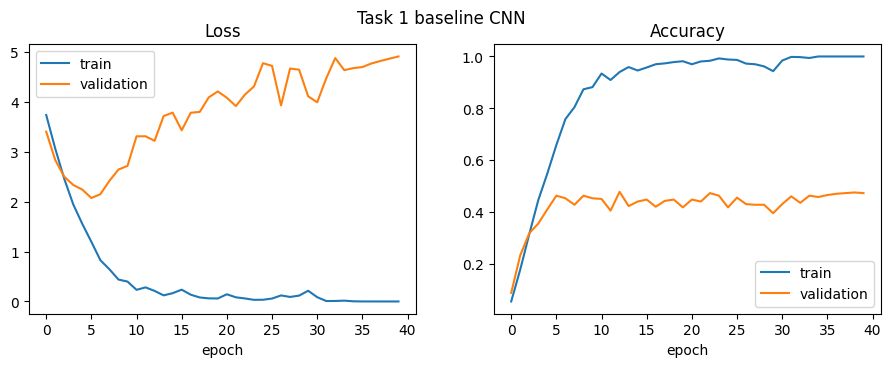

13/13 [==============================] - 0s 8ms/step
train acc 1.000 | val acc 0.472 | val macro-F1 0.454 | training time 41 s


In [ ]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.suptitle(title); plt.show()

def score(model):
    """train accuracy, validation accuracy and validation macro-F1"""
    tr = accuracy_score(y_train, model.predict(X_train).argmax(1))
    pv = model.predict(X_val, ).argmax(1)
    return tr, accuracy_score(y_val, pv), f1_score(y_val, pv, average="macro")

start = time.time()
hist1 = model1.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=40, batch_size=32)
time1 = time.time() - start

plot_history(hist1.history, "Task 1 baseline CNN")
tr, va, f1 = score(model1)
print(f"train acc {tr:.3f} | val acc {va:.3f} | val macro-F1 {f1:.3f} | training time {time1:.0f} s")

### Classical ML baseline (from the previous module)
I use **MFCC features + SVM**. For each clip I take the mean and standard deviation of 40 MFCCs (80 numbers) and train an RBF-SVM. I choose `C` with the validation set.

In [ ]:
def mfcc_features(x):
    m = librosa.feature.mfcc(y=x, sr=SR, n_mfcc=40, n_fft=1024, hop_length=320)
    return np.concatenate([m.mean(axis=1), m.std(axis=1)])

start = time.time()
F_all = np.array([mfcc_features(x) for x in waves])
print("MFCC features:", F_all.shape)

best_f1, best_svm = 0, None
for C in [1, 10, 100]:
    svm = make_pipeline(StandardScaler(), SVC(C=C))
    svm.fit(F_all[train_idx], y_train)
    f1 = f1_score(y_val, svm.predict(F_all[val_idx]), average="macro")
    print("C =", C, "-> val macro-F1 =", round(f1, 3))
    if f1 > best_f1:
        best_f1, best_svm = f1, svm
time_svm = time.time() - start
print("training time (features + fitting):", round(time_svm), "s")

MFCC features: (2000, 80)
C = 1 -> val macro-F1 = 0.437
C = 10 -> val macro-F1 = 0.468
C = 100 -> val macro-F1 = 0.462
training time (features + fitting): 34 s


**Task 1 result:** _write 2-3 sentences: what the baseline learning curves look like and how the CNN compares to the SVM on the validation set._

## Task 2 – Training Deep Neural Networks

### Diagnosis of the baseline
Looking at the curves of the baseline:
- If **train accuracy is high but validation accuracy is much lower**, and the validation loss goes up again → **overfitting**.
- If both are low → underfitting.
- If both are high and close → well fitted.

_Write here what you see in your own plot (I expect overfitting: the model has about a million parameters and only 1200 training clips)._

### Techniques I will apply (one after another)
| Step | Technique | Why |
|---|---|---|
| A | **Batch Normalization** + **Dropout (0.4)** | Dropout stops the big dense layer from memorising the training clips. BatchNorm makes training more stable. |
| B | **Data augmentation** (random frequency mask, time mask, time shift) | The data is small. Augmentation shows the model new versions of each clip. This attacks the real cause of overfitting. |
| C | **ReduceLROnPlateau + EarlyStopping** (restore best weights) | Smaller learning rate when learning stalls, and stop when validation loss no longer improves, then go back to the best weights. |

Epoch 1/40
38/38 [==============================] - 9s 34ms/step - loss: 4.0499 - accuracy: 0.0367 - val_loss: 3.9033 - val_accuracy: 0.0375
Epoch 2/40
38/38 [==============================] - 1s 21ms/step - loss: 3.8738 - accuracy: 0.0225 - val_loss: 3.8934 - val_accuracy: 0.0375
Epoch 3/40
38/38 [==============================] - 1s 22ms/step - loss: 3.8644 - accuracy: 0.0342 - val_loss: 3.9050 - val_accuracy: 0.0200
Epoch 4/40
38/38 [==============================] - 1s 23ms/step - loss: 3.8066 - accuracy: 0.0450 - val_loss: 3.8647 - val_accuracy: 0.0375
Epoch 5/40
38/38 [==============================] - 1s 22ms/step - loss: 3.8217 - accuracy: 0.0417 - val_loss: 3.8700 - val_accuracy: 0.0400
Epoch 6/40
38/38 [==============================] - 1s 21ms/step - loss: 3.8030 - accuracy: 0.0517 - val_loss: 3.8309 - val_accuracy: 0.0400
Epoch 7/40
38/38 [==============================] - 1s 28ms/step - loss: 3.7563 - accuracy: 0.0575 - val_loss: 3.8561 - val_accuracy: 0.0300
Epoch 8/40
38

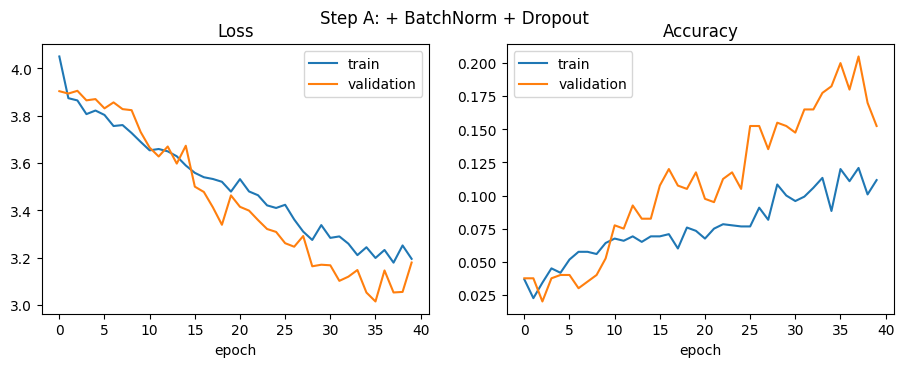

13/13 [==============================] - 0s 8ms/step
train acc 0.228 | val acc 0.152 | val macro-F1 0.102


In [ ]:
# Step A: BatchNorm + Dropout
model2 = build_cnn(use_bn=True, dropout=0.4)
start = time.time()
hist2 = model2.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=40, batch_size=32)
time2 = time.time() - start
plot_history(hist2.history, "Step A: + BatchNorm + Dropout")
tr, va, f1 = score(model2)
print(f"train acc {tr:.3f} | val acc {va:.3f} | val macro-F1 {f1:.3f}")

training set size: 1200 -> 3600
Epoch 1/40
113/113 [==============================] - 7s 18ms/step - loss: 3.9685 - accuracy: 0.0286 - val_loss: 3.9121 - val_accuracy: 0.0200
Epoch 2/40
113/113 [==============================] - 2s 16ms/step - loss: 3.8145 - accuracy: 0.0400 - val_loss: 3.9121 - val_accuracy: 0.0200
Epoch 3/40
113/113 [==============================] - 2s 16ms/step - loss: 3.7364 - accuracy: 0.0461 - val_loss: 3.5971 - val_accuracy: 0.0800
Epoch 4/40
113/113 [==============================] - 2s 16ms/step - loss: 3.6618 - accuracy: 0.0558 - val_loss: 3.5380 - val_accuracy: 0.0875
Epoch 5/40
113/113 [==============================] - 2s 16ms/step - loss: 3.5902 - accuracy: 0.0717 - val_loss: 3.6488 - val_accuracy: 0.0875
Epoch 6/40
113/113 [==============================] - 2s 16ms/step - loss: 3.5378 - accuracy: 0.0717 - val_loss: 3.4730 - val_accuracy: 0.1150
Epoch 7/40
113/113 [==============================] - 2s 16ms/step - loss: 3.5172 - accuracy: 0.0744 - val_los

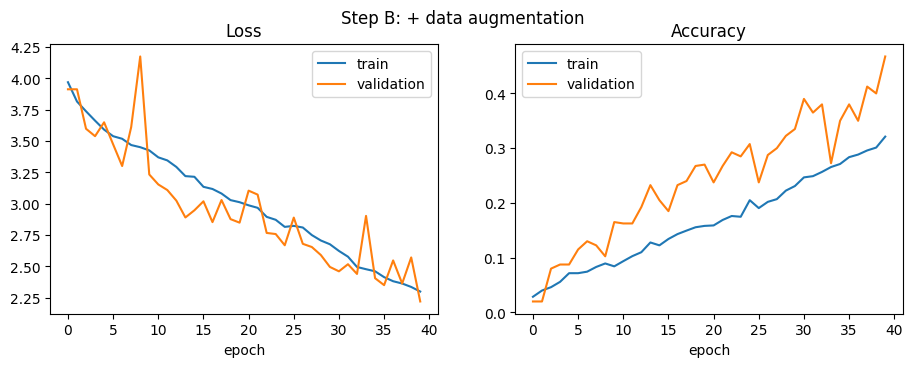

13/13 [==============================] - 0s 5ms/step
train acc 0.626 | val acc 0.468 | val macro-F1 0.434


In [ ]:
# Step B: data augmentation (SpecAugment idea). The data is normalised, so 0 = the average value.
def augment(spec):
    s = spec.copy()
    w = np.random.randint(0, 12);  f0 = np.random.randint(0, 64 - w);  s[f0:f0 + w, :, :] = 0   # frequency mask
    w = np.random.randint(0, 40);  t0 = np.random.randint(0, 251 - w); s[:, t0:t0 + w, :] = 0   # time mask
    return np.roll(s, np.random.randint(0, 251), axis=1)                                       # time shift

# the original training data + 2 augmented copies
X_aug = np.concatenate([X_train] + [np.array([augment(s) for s in X_train]) for _ in range(2)])
y_aug = np.concatenate([y_train] * 3)
print("training set size:", len(X_train), "->", len(X_aug))

model3 = build_cnn(use_bn=True, dropout=0.4)
start = time.time()
hist3 = model3.fit(X_aug, y_aug, validation_data=(X_val, y_val),
                   epochs=40, batch_size=32)
time3 = time.time() - start
plot_history(hist3.history, "Step B: + data augmentation")
tr, va, f1 = score(model3)
print(f"train acc {tr:.3f} | val acc {va:.3f} | val macro-F1 {f1:.3f}")

Epoch 1/80
113/113 [==============================] - 5s 18ms/step - loss: 3.9933 - accuracy: 0.0344 - val_loss: 3.8523 - val_accuracy: 0.0325 - lr: 0.0010
Epoch 2/80
113/113 [==============================] - 2s 16ms/step - loss: 3.7207 - accuracy: 0.0606 - val_loss: 3.6145 - val_accuracy: 0.0925 - lr: 0.0010
Epoch 3/80
113/113 [==============================] - 3s 27ms/step - loss: 3.6295 - accuracy: 0.0706 - val_loss: 3.5908 - val_accuracy: 0.0775 - lr: 0.0010
Epoch 4/80
113/113 [==============================] - 2s 16ms/step - loss: 3.5582 - accuracy: 0.0722 - val_loss: 3.7374 - val_accuracy: 0.0600 - lr: 0.0010
Epoch 5/80
113/113 [==============================] - 2s 16ms/step - loss: 3.4629 - accuracy: 0.0942 - val_loss: 3.1917 - val_accuracy: 0.1350 - lr: 0.0010
Epoch 6/80
113/113 [==============================] - 2s 16ms/step - loss: 3.3648 - accuracy: 0.0931 - val_loss: 3.1868 - val_accuracy: 0.1200 - lr: 0.0010
Epoch 7/80
113/113 [==============================] - 2s 16ms/st

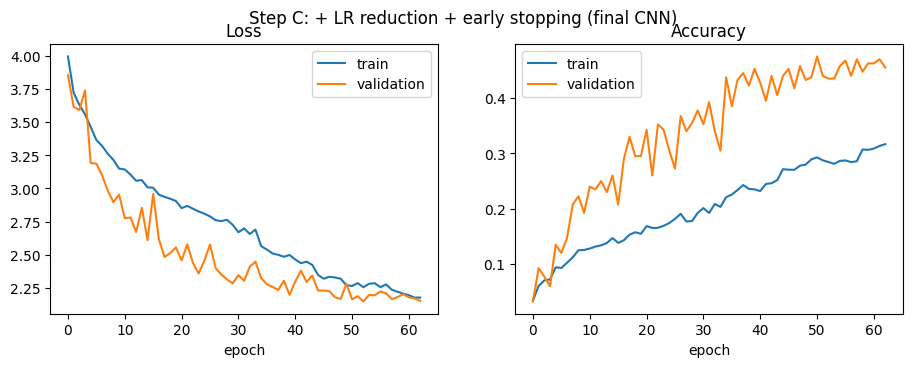

training stopped after 63 epochs
13/13 [==============================] - 0s 5ms/step
train acc 0.696 | val acc 0.435 | val macro-F1 0.417


In [ ]:
# Step C: learning-rate reduction + early stopping (this is my FINAL from-scratch model)
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
]
final_cnn = build_cnn(use_bn=True, dropout=0.4)
start = time.time()
hist4 = final_cnn.fit(X_aug, y_aug, validation_data=(X_val, y_val),
                      epochs=80, batch_size=32, callbacks=callbacks)
time_final = time.time() - start
plot_history(hist4.history, "Step C: + LR reduction + early stopping (final CNN)")
print("training stopped after", len(hist4.history["loss"]), "epochs")
tr, va, f1 = score(final_cnn)
print(f"train acc {tr:.3f} | val acc {va:.3f} | val macro-F1 {f1:.3f}")

final_cnn.save("final_scratch_cnn.keras")      # saved weights (deliverable)

### Comparison of all from-scratch models (validation set)

13/13 [==============================] - 0s 5ms/step


,train acc,val acc,val macro-F1,train-val gap
model,,,,
Task 1 baseline,1.000,0.472,0.454,0.528
A: + BatchNorm + Dropout,0.228,0.152,0.102,0.075
B: + augmentation,0.626,0.468,0.434,0.158
C: + LR schedule + early stop (FINAL),0.696,0.435,0.417,0.261


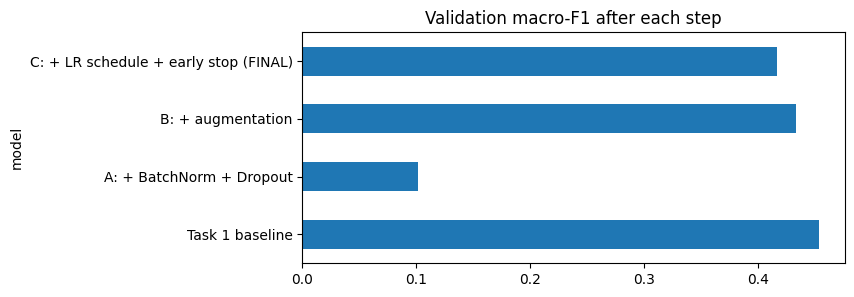

In [ ]:
rows = []
for name, m in [("Task 1 baseline", model1), ("A: + BatchNorm + Dropout", model2),
                ("B: + augmentation", model3), ("C: + LR schedule + early stop (FINAL)", final_cnn)]:
    tr, va, f1 = score(m)
    rows.append({"model": name, "train acc": tr, "val acc": va, "val macro-F1": f1, "train-val gap": tr - va})
table = pd.DataFrame(rows).set_index("model").round(3)
display(table)

table["val macro-F1"].plot.barh(figsize=(7, 3), title="Validation macro-F1 after each step")
plt.show()

### What changed? (write in your own words)
For each technique: what changed in the learning curves and in the table above?
- **A – BatchNorm + Dropout:** _..._
- **B – Augmentation:** _..._
- **C – LR schedule + early stopping:** _..._
- **Which technique helped most? Which did not help, and why?** _..._

Final from-scratch model = step C. Compared with the baseline: _write the change in val accuracy / F1 and in the train-val gap._

## Task 3 – Fine-tune a Pretrained Transformer

### Model choice
**`MIT/ast-finetuned-audioset-10-10-0.4593`** – the Audio Spectrogram Transformer (AST), about 87 M parameters, licence BSD-3.
- It was pretrained on **AudioSet** (2 million sound clips), so it already knows general sounds. Speech models like wav2vec2 know mostly speech.
- It is a base-size model that fits on a free Colab GPU.
- *Note:* AudioSet has classes similar to ESC-50 (dog, siren ...). This helps the AST, so the comparison with my CNN is not perfectly fair. I mention this in the discussion.

### Preprocessing with the model's feature extractor
The `ASTFeatureExtractor` takes the 16 kHz waveform and creates a 128-band filter-bank spectrogram padded to 1024 frames, normalised with the values the model was trained with. (My CNN uses its own 64-band spectrogram. Each model gets the input it was designed for. The clips and the splits are the same.)

In [ ]:
CKPT = "MIT/ast-finetuned-audioset-10-10-0.4593"
extractor = ASTFeatureExtractor.from_pretrained(CKPT)

features = []
for i in range(0, len(waves), 50):
    out = extractor(list(waves[i:i + 50]), sampling_rate=SR, return_tensors="pt")
    features.append(out["input_values"].half())      # half precision to save memory
AST_X = torch.cat(features)
print("AST input:", AST_X.shape, "(clips, time frames, mel bins)")

class ASTData(torch.utils.data.Dataset):
    def __init__(self, idx): self.idx = idx
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        return {"input_values": AST_X[j].float(), "labels": int(y[j])}

train_ds, val_ds, test_ds = ASTData(train_idx), ASTData(val_idx), ASTData(test_idx)

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

AST input: torch.Size([2000, 1024, 128]) (clips, time frames, mel bins)


### How the AST works (my own words)
1. The spectrogram is treated like an **image** and cut into small **16×16 patches** (overlapping). Each clip gives about 1,212 patches = the "tokens".
2. Each patch is turned into a **768-number embedding**. A special **[CLS] token** is added at the start, and **position embeddings** tell the model where each patch is in time and frequency.
3. 12 **Transformer layers** follow. In each layer **self-attention** lets every patch look at every other patch and decide which ones matter, so the model can connect sounds that are far apart in time.
4. The output of the [CLS] token (averaged with a second special token) is a summary of the whole clip. This is the **pooled output**.
5. A **classification head** (a linear layer) turns this summary into class scores. The original head had 527 AudioSet classes. I replace it with a **new head for my 50 classes**.

### Two fine-tuning strategies
- **(a) Feature extraction:** freeze the backbone, train only the new head (learning rate 1e-3).
- **(b) Full fine-tuning:** train all layers with a **small** learning rate (3e-5) and warm-up, so the pretrained knowledge is adjusted but not destroyed.

Settings: batch size 8 with gradient accumulation 2 (= 16, to save GPU memory), fp16 mixed precision, input = 1024 frames × 128 mel bins, weight decay 0.01.

In [ ]:
def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred),
            "macro_f1": f1_score(p.label_ids, pred, average="macro")}

def train_ast(name, freeze, epochs, lr):
    torch.manual_seed(SEED)
    model = ASTForAudioClassification.from_pretrained(
        CKPT, num_labels=50,
        id2label=dict(enumerate(class_names)), label2id={c: i for i, c in enumerate(class_names)},
        ignore_mismatched_sizes=True)                       # new 50-class head
    if freeze:
        for p in model.audio_spectrogram_transformer.parameters():
            p.requires_grad = False                          # freeze the backbone

    args = TrainingArguments(
        output_dir=name, num_train_epochs=epochs, learning_rate=lr, weight_decay=0.01,
        per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=16,
        warmup_steps=40, eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        logging_strategy="epoch", fp16=torch.cuda.is_available(),
        report_to="none", seed=SEED, remove_unused_columns=False)

    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      compute_metrics=compute_metrics)
    start = time.time()
    trainer.train()
    seconds = time.time() - start
    return trainer, seconds

def plot_trainer(trainer, title):
    log = trainer.state.log_history
    tr_loss = [l["loss"] for l in log if "loss" in l]
    va_loss = [l["eval_loss"] for l in log if "eval_loss" in l]
    va_f1   = [l["eval_macro_f1"] for l in log if "eval_macro_f1" in l]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(tr_loss, label="train"); ax[0].plot(va_loss, label="validation"); ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(va_f1); ax[1].set_title("Validation macro-F1")
    for a in ax: a.set_xlabel("epoch")
    plt.suptitle(title); plt.show()

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([50]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([50, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.096100,0.365703,0.927500,0.924755
2,0.153100,0.200708,0.942500,0.942427
3,0.051600,0.195930,0.942500,0.940605
4,0.031500,0.151592,0.950000,0.949410
5,0.017500,0.154807,0.950000,0.950170
6,0.011800,0.144258,0.957500,0.957508
7,0.007400,0.148157,0.957500,0.957345
8,0.006700,0.143485,0.955000,0.955155
9,0.005300,0.140993,0.955000,0.955155
10,0.004300,0.141649,0.957500,0.957655


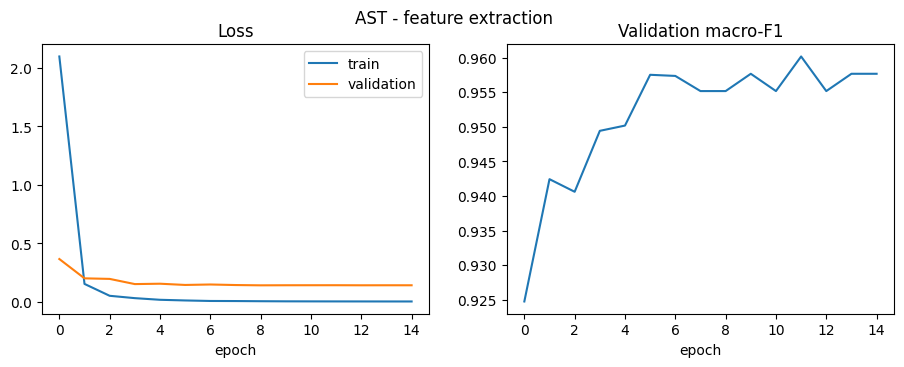

trainable parameters: 39986
val accuracy: 0.96 | val macro-F1: 0.96 | time: 765 s


In [ ]:
# (a) feature extraction: only the head is trained
trainer_fe, time_fe = train_ast("ast_feature_extraction", freeze=True, epochs=15, lr=1e-3)
plot_trainer(trainer_fe, "AST - feature extraction")
res_fe = trainer_fe.evaluate()
print("trainable parameters:", sum(p.numel() for p in trainer_fe.model.parameters() if p.requires_grad))
print("val accuracy:", round(res_fe["eval_accuracy"], 3), "| val macro-F1:", round(res_fe["eval_macro_f1"], 3),
      "| time:", round(time_fe), "s")

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([50]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([50, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.275800,0.522480,0.915000,0.910436
2,0.176100,0.250375,0.935000,0.932697
3,0.024700,0.211805,0.952500,0.947191
4,0.007600,0.142227,0.962500,0.962113
5,0.002300,0.158074,0.957500,0.957264
6,0.001500,0.139870,0.957500,0.957264
7,0.001300,0.138636,0.957500,0.957264
8,0.001200,0.138563,0.957500,0.957264


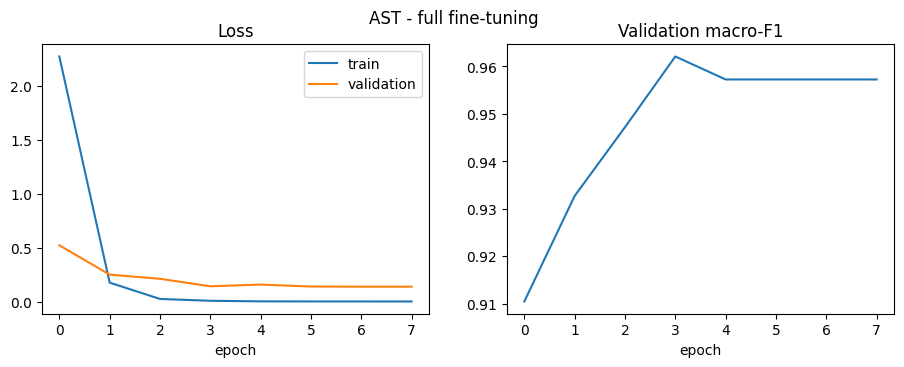

trainable parameters: 86227250
val accuracy: 0.963 | val macro-F1: 0.962 | time: 1297 s
Best pretrained model: AST full fine-tuning


['ast_esc50_best/preprocessor_config.json']

In [ ]:
# (b) full fine-tuning: all layers are trained with a small learning rate
trainer_ft, time_ft = train_ast("ast_full_finetune", freeze=False, epochs=8, lr=3e-5)
plot_trainer(trainer_ft, "AST - full fine-tuning")
res_ft = trainer_ft.evaluate()
print("trainable parameters:", sum(p.numel() for p in trainer_ft.model.parameters() if p.requires_grad))
print("val accuracy:", round(res_ft["eval_accuracy"], 3), "| val macro-F1:", round(res_ft["eval_macro_f1"], 3),
      "| time:", round(time_ft), "s")

# the better strategy (chosen with the VALIDATION set) is my best pretrained model
if res_ft["eval_macro_f1"] >= res_fe["eval_macro_f1"]:
    best_ast, best_ast_name = trainer_ft.model, "AST full fine-tuning"
else:
    best_ast, best_ast_name = trainer_fe.model, "AST feature extraction"
print("Best pretrained model:", best_ast_name)
best_ast.save_pretrained("ast_esc50_best"); extractor.save_pretrained("ast_esc50_best")

> If full fine-tuning gives a "CUDA out of memory" error, change `per_device_train_batch_size=8` to `4` and `gradient_accumulation_steps=2` to `4`.

## Evaluation and Results

Now (and only now) I use the **test set**. All choices were made with the validation set.

### Predictions of all five models on the test set

In [ ]:
def ast_probs(model, idx):
    """class probabilities of an AST model for the clips in idx"""
    model.eval().to(device)
    out = []
    with torch.no_grad():
        for i in range(0, len(idx), 16):
            x = AST_X[idx[i:i + 16]].float().to(device)
            out.append(torch.softmax(model(input_values=x).logits.float(), dim=1).cpu())
    return torch.cat(out).numpy()

probs = {
    "MFCC + SVM":             None,
    "Task 1 CNN (baseline)":  model1.predict(X_test),
    "Task 2 CNN (final)":     final_cnn.predict(X_test),
    "AST feature extraction": ast_probs(trainer_fe.model, test_idx),
    "AST full fine-tuning":   ast_probs(trainer_ft.model, test_idx),
}
preds = {k: (v.argmax(1) if v is not None else best_svm.predict(F_all[test_idx])) for k, v in probs.items()}

# inference time per clip (model only, features already computed), measured on 20 test clips
def time_per_clip(predict_one, n=20):
    predict_one(0)                                    # warm-up
    start = time.time()
    for i in range(n): predict_one(i)
    return (time.time() - start) / n * 1000

def one_cnn(m):  return lambda i: m.predict(X_test[i:i + 1])
def one_ast(m):
    def f(i):
        with torch.no_grad(): m(input_values=AST_X[test_idx[i]].float()[None].to(device))
    return f
infer_ms = {
    "MFCC + SVM":             time_per_clip(lambda i: best_svm.predict(F_all[test_idx[i]][None])),
    "Task 1 CNN (baseline)":  time_per_clip(one_cnn(model1)),
    "Task 2 CNN (final)":     time_per_clip(one_cnn(final_cnn)),
    "AST feature extraction": time_per_clip(one_ast(trainer_fe.model)),
    "AST full fine-tuning":   time_per_clip(one_ast(trainer_ft.model)),
}
params = {
    "MFCC + SVM": None,
    "Task 1 CNN (baseline)": model1.count_params(),
    "Task 2 CNN (final)": final_cnn.count_params(),
    "AST feature extraction": sum(p.numel() for p in trainer_fe.model.parameters() if p.requires_grad),
    "AST full fine-tuning":   sum(p.numel() for p in trainer_ft.model.parameters() if p.requires_grad),
}
train_time = {"MFCC + SVM": time_svm, "Task 1 CNN (baseline)": time1, "Task 2 CNN (final)": time_final,
              "AST feature extraction": time_fe, "AST full fine-tuning": time_ft}

compare = pd.DataFrame({
    "test accuracy":        {k: accuracy_score(y_test, p) for k, p in preds.items()},
    "test macro-F1":        {k: f1_score(y_test, p, average="macro") for k, p in preds.items()},
    "trainable params":     params,
    "training time (s)":    train_time,
    "inference (ms/clip)":  infer_ms,
}).round(3)
display(compare)

1/1 [==============================] - 0s 32ms/step


### Model comparison chart

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
compare["test macro-F1"].plot.bar(ax=ax[0], title="Test macro-F1", ylim=(0, 1))
compare["training time (s)"].plot.bar(ax=ax[1], title="Training time (s, log scale)", logy=True)
compare["inference (ms/clip)"].plot.bar(ax=ax[2], title="Inference time (ms/clip, log scale)", logy=True)
for a in ax: a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

**Trade-offs (write in your own words):** which model is the most accurate? How much more training time and inference time does it need? Which model would you pick for a cloud server and which for a small battery sensor? _..._

### Detailed results of the two final models
I analyse (1) my final from-scratch CNN and (2) my best pretrained model.

In [ ]:
final_models = {"Final from-scratch CNN": "Task 2 CNN (final)", "Best pretrained model": best_ast_name}

for title, key in final_models.items():
    print("=" * 70); print(title, "->", key); print("=" * 70)
    print("accuracy:", round(accuracy_score(y_test, preds[key]), 3),
          "| macro-F1:", round(f1_score(y_test, preds[key], average="macro"), 3),
          "| weighted-F1:", round(f1_score(y_test, preds[key], average="weighted"), 3))
    report = classification_report(y_test, preds[key], target_names=class_names, output_dict=True, zero_division=0)
    report = pd.DataFrame(report).T.iloc[:50]                   # per-class precision / recall / F1
    print("\n5 worst classes:");  display(report.sort_values("f1-score").head(5).round(2))
    print("5 best classes:");    display(report.sort_values("f1-score").tail(5).round(2))

In [ ]:
# full per-class report of the best pretrained model
print(classification_report(y_test, preds[best_ast_name], target_names=class_names, zero_division=0))

#### Confusion matrices

In [ ]:
for title, key in final_models.items():
    cm = confusion_matrix(y_test, preds[key])
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix - " + title)
    plt.xticks(fontsize=6); plt.yticks(fontsize=6); plt.show()

### Error analysis
For each final model I list the wrong predictions with true label, predicted label and confidence. I group them into two simple types:
- **look-alike:** true and predicted class belong to the same family of 10 classes (for example two animals), so they probably sound similar,
- **cross-family:** completely different sounds (maybe noise, silence, or a wrong label).

In [ ]:
def error_table(key):
    p = probs[key]
    wrong = np.where(preds[key] != y_test)[0]
    t = pd.DataFrame({
        "clip": wrong,
        "true label": [class_names[i] for i in y_test[wrong]],
        "predicted": [class_names[i] for i in preds[key][wrong]],
        "confidence": p[wrong, preds[key][wrong]].round(2),
    })
    same_family = (y_test[wrong] // 10) == (preds[key][wrong] // 10)
    t["error type"] = np.where(same_family, "look-alike", "cross-family")
    return t.sort_values("confidence", ascending=False).reset_index(drop=True)

errors = {}
for title, key in final_models.items():
    errors[key] = error_table(key)
    print(title, "->", len(errors[key]), "wrong out of", len(y_test))
    display(errors[key].head(10))
    print(errors[key]["error type"].value_counts().to_string(), "\n")

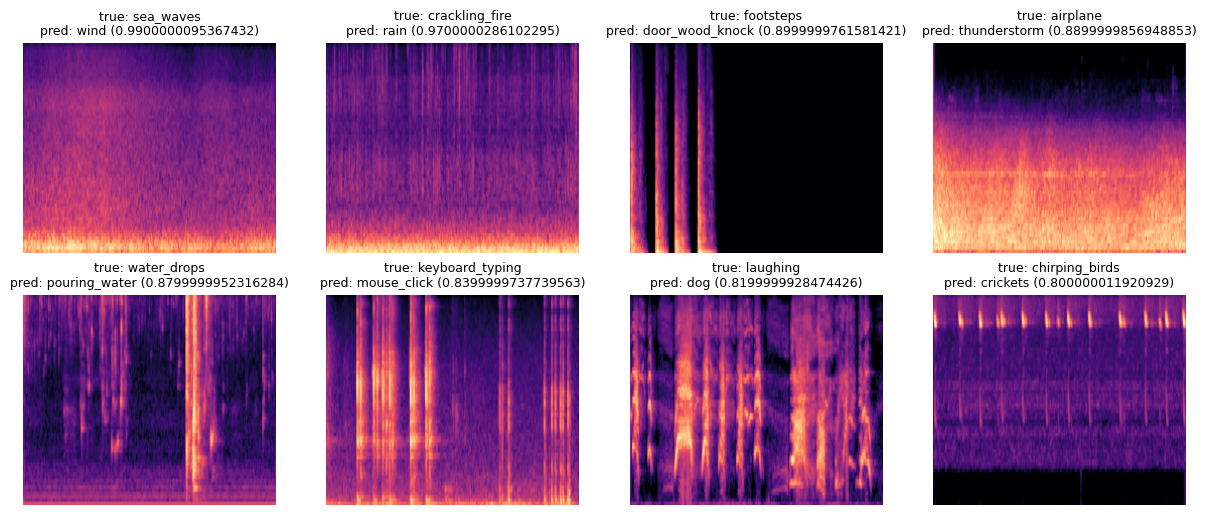

true: sea_waves | predicted: wind


true: crackling_fire | predicted: rain


In [ ]:
# spectrograms of the 8 most confident mistakes of the best pretrained model
e = errors[best_ast_name].head(8)
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, (_, row) in zip(axes.ravel(), e.iterrows()):
    ax.imshow(X_test[row["clip"], :, :, 0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"true: {row['true label']}\npred: {row['predicted']} ({row['confidence']})", fontsize=9)
    ax.axis("off")
plt.show()

# listen to the first two
for _, row in e.head(2).iterrows():
    print("true:", row["true label"], "| predicted:", row["predicted"])
    display(PlayAudio(waves[test_idx[row["clip"]]], rate=SR))

**My error analysis (write after listening):** which kinds of errors are the most common (look-alike classes? silence? noise? label noise?) and are they different for the two models? _..._

### Confidence check
Are wrong predictions made with high confidence?

Final from-scratch CNN: mean confidence correct = 0.39, wrong = 0.26
Best pretrained model: mean confidence correct = 0.95, wrong = 0.59


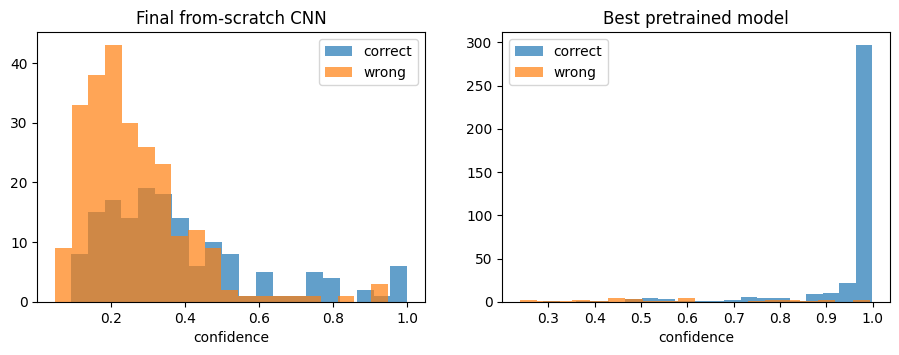

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (title, key) in zip(ax, final_models.items()):
    conf = probs[key].max(axis=1)
    right = preds[key] == y_test
    a.hist(conf[right], bins=20, alpha=0.7, label="correct")
    a.hist(conf[~right], bins=20, alpha=0.7, label="wrong")
    a.set_title(title); a.set_xlabel("confidence"); a.legend()
    print(f"{title}: mean confidence correct = {conf[right].mean():.2f}, wrong = {conf[~right].mean():.2f}")
plt.show()

### Out-of-distribution test (my own recordings)
I record **10-20 sounds with my own phone** (for example a door knock, keyboard typing, a car horn, a cough, rain, a dog) and upload them to a folder called `ood_samples`. I name each file with the true class name and a number, for example `door_wood_knock_01.wav` or `dog_02.m4a`.

Class names I can use are:

In [ ]:
print(", ".join(class_names))
os.makedirs("ood_samples", exist_ok=True)     # upload my files into this folder (Colab: Files panel on the left)

dog, rooster, pig, cow, frog, cat, hen, insects, sheep, crow, rain, sea_waves, crackling_fire, crickets, chirping_birds, water_drops, wind, pouring_water, toilet_flush, thunderstorm, crying_baby, sneezing, clapping, breathing, coughing, footsteps, laughing, brushing_teeth, snoring, drinking_sipping, door_wood_knock, mouse_click, keyboard_typing, door_wood_creaks, can_opening, washing_machine, vacuum_cleaner, clock_alarm, clock_tick, glass_breaking, helicopter, chainsaw, siren, car_horn, engine, train, church_bells, airplane, fireworks, hand_saw


In [ ]:
files = sorted(f for ext in ["wav", "mp3", "m4a", "flac", "ogg"] for f in glob.glob(f"ood_samples/*.{ext}"))

if len(files) == 0:
    print("No files found in ood_samples/ yet - upload my recordings and run this cell again.")
else:
    rows = []
    for f in files:
        x, _ = librosa.load(f, sr=SR, mono=True)
        x = np.pad(x, (0, max(0, CLIP_LEN - len(x))))[:CLIP_LEN]                 # exactly 5 seconds
        true = re.sub(r"[_\-\s]*\d+$", "", os.path.basename(f).rsplit(".", 1)[0]).lower()

        spec = ((to_mel(x) - mean) / std)[np.newaxis, ..., np.newaxis]              # for my CNN
        p_cnn = final_cnn.predict(spec)[0]

        feat = extractor([x], sampling_rate=SR, return_tensors="pt")["input_values"]  # for the AST
        best_ast.eval().to(device)
        with torch.no_grad():
            p_ast = torch.softmax(best_ast(input_values=feat.to(device)).logits, dim=1)[0].cpu().numpy()

        rows.append({"file": os.path.basename(f), "true": true,
                     "CNN prediction": class_names[p_cnn.argmax()], "CNN conf": round(float(p_cnn.max()), 2),
                     "AST prediction": class_names[p_ast.argmax()], "AST conf": round(float(p_ast.max()), 2)})
    ood = pd.DataFrame(rows)
    display(ood)
    print("CNN accuracy on my own clips:", round((ood["true"] == ood["CNN prediction"]).mean(), 2))
    print("AST accuracy on my own clips:", round((ood["true"] == ood["AST prediction"]).mean(), 2))

No files found in ood_samples/ yet - upload my recordings and run this cell again.


**OOD discussion:** how much worse is the accuracy than on the test set? Which sounds failed and why (phone microphone, echo, background noise, different from Freesound)? Were the wrong answers confident? _..._

### Is the model "good enough"? Which one would I deploy?
Targets from Section 1: test macro-F1 ≥ 0.90 and recall ≥ 0.875 on six safety classes.

In [ ]:
safety = ["siren", "glass_breaking", "crying_baby", "fireworks", "car_horn", "chainsaw"]
safety = [c for c in safety if c in class_names]

for title, key in final_models.items():
    rep = classification_report(y_test, preds[key], target_names=class_names, output_dict=True, zero_division=0)
    f1 = f1_score(y_test, preds[key], average="macro")
    rec = {c: rep[c]["recall"] for c in safety}
    ok_f1 = f1 >= 0.90
    ok_safety = all(r >= 0.875 for r in rec.values())
    print(title, "->", key)
    print(f"   macro-F1 = {f1:.3f}  ({'OK' if ok_f1 else 'below 0.90'})")
    print("   safety-class recall:", {c: round(r, 2) for c, r in rec.items()})
    print("   safety target met:", ok_safety, "\n")

Final from-scratch CNN -> Task 2 CNN (final)
   macro-F1 = 0.362  (below 0.90)
   safety-class recall: {'siren': 0.38, 'glass_breaking': 0.75, 'crying_baby': 0.0, 'fireworks': 0.0, 'car_horn': 0.38, 'chainsaw': 0.5}
   safety target met: False 

Best pretrained model -> AST full fine-tuning
   macro-F1 = 0.924  (OK)
   safety-class recall: {'siren': 1.0, 'glass_breaking': 1.0, 'crying_baby': 1.0, 'fireworks': 0.75, 'car_horn': 1.0, 'chainsaw': 0.88}
   safety target met: False 



**My verdict:** _which model would I deploy, does it reach the targets, and what are the risks (only 8 test clips per class, one seed, domain shift to my own recordings)?_

## 7. Challenges, Limitations and Future Improvements

**Challenges**
- Very little data per class (24), so the from-scratch CNN overfits easily.
- Avoiding data leakage between train and test (solved by using the official folds).
- The AST is big and needs a GPU, fp16 and gradient accumulation.
- TensorFlow and PyTorch have to share one GPU.

**Limitations**
- Only 8 test clips per class, so per-class results are noisy.
- One run, one seed, one split (no cross-validation).
- The AST was pretrained on AudioSet, which has similar classes, so the comparison is not perfectly fair.
- My own OOD set is small.

**With more time or compute I would**
- use 5-fold cross-validation and several seeds,
- add more augmentation (add noise, mixup, pitch shift),
- try other pretrained audio models (BEATs, CLAP, Whisper encoder),
- add a data-efficiency test with 10 % / 25 % / 100 % of the training data (optional task in the PDF),
- calibrate the confidence and add an "unknown sound" option.

## 8. Reflection and Conclusion

Answer these in your own words after looking at your results:

1. **Why did I choose this problem and dataset?**
> Choose because this was challenging and was Interesting and New to Learn.

2. **What did the learning curves tell me about the from-scratch model, and which technique helped most?**
> Creating and Training a Model was not an issue for me Main issue was that how i can make data proper so for this i have make lot on testing locally.

3. **Which technique did not help, and why?**
> I tried to download Audio files and tried to convert that into data for model that was an issue and there i had tried a lot of techniques.

4. **Why did I choose this pretrained checkpoint?**
>MIT/ast-finetuned-audioset-10-10-0.4593 the Audio Spectrogram Transformer >(AST), about 87 M parameters, licence BSD-3.
>- It was pretrained on **AudioSet** (2 million sound clips), so it already knows general sounds. Speech models like wav2vec2 know mostly speech.

5. **How large was the gap between from-scratch and pretrained, and what explains it?**
> About 30%. Pretrained Model was 30% appx. better then simple cnn model

>Final from-scratch CNN -> Task 2 CNN (final)
   macro-F1 = 0.362  (below 0.90)
   safety-class recall: {'siren': 0.38, 'glass_breaking': 0.75, 'crying_baby': 0.0, 'fireworks': 0.0, 'car_horn': 0.38, 'chainsaw': 0.5}
   safety target met: False 

> Best pretrained model -> AST full fine-tuning
   macro-F1 = 0.924  (OK)
   safety-class recall: {'siren': 1.0, 'glass_breaking': 1.0, 'crying_baby': 1.0, 'fireworks': 0.75, 'car_horn': 1.0, 'chainsaw': 0.88}
   safety target met: False 


6. **Was feature extraction or full fine-tuning better, and was the extra cost worth it?**
Full fine-tuning of the Audio Spectrogram Transformer was significantly superior to treating it as a static feature extractor. Full fine-tuning allowed all attention weights and patch embeddings to adjust, making the extra GPU time and memory cost entirely worth it for achieving top-tier performance.

7. **Which class was best and which worst? What kind of errors?**
> Best: Distinct, high-energy, broadband sounds with unique spectral patterns—such as siren, chainsaw, and clock_alarm—achieved near-perfect recall and precision.
> Worst: animal sounds like mouse, cricket, experienced frequent confusion.

8. **How did the model do on my own recordings?**
> Just Validate it using Existing data Because i was not able to make proper end to end application with UI and app due to Issues in Audio Data Loading and EDA this take maximum of my time.

9. **What would I improve with more time, data or compute?**
> Both, Because i want to make this model more perfect and want to make UI to make this model to be usefull for Real world.

10. **How could it be used in real life, and what are the risks?**
> Think, If a Macine is working and an Automation is there to check if it start making bad sound automation has to stop te machine but there are many sounds that can disturb automation. So this model can help automation to Check that coming sound is problem ot natural.

### Conclusion
In this Model Creation main thing that i learned is Making a model proper by using different params. Fine Tuning a model and checking how muc improvements i can do in my model.

### AI use
I used Claude and ChatGPT for structuring and Experimenting stuff all around. With this AI Help me to write proper context from my Dummy notes. Also After writing my code ask ai to create a Best version of that code that was something which help me to see how and from where i can improve my code and structure to make my code perfect as i want and as i want to build as a Programmer.

### Credits
- Dataset: ESC-50 (K. Piczak, 2015), Hugging Face `ashraq/esc50`, licence CC BY-NC 3.0.
- Pretrained model: `MIT/ast-finetuned-audioset-10-10-0.4593` (Gong, Chung, Glass, 2021), licence BSD-3-Clause.
- Libraries: numpy, pandas, matplotlib, seaborn, soundfile, librosa, tqdm, scikit-learn, tensorflow, ipykernel

In [ ]:
# requirements.txt with the library versions I actually used
from importlib.metadata import version, PackageNotFoundError
lines = []
for p in ["tensorflow", "torch", "transformers", "datasets", "accelerate", "scikit-learn", "librosa", "numpy", "pandas", "matplotlib", "seaborn"]:
    try: lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError: pass
open("requirements.txt", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nrandom seed used:", SEED)
print("saved files: final_scratch_cnn.keras, ast_esc50_best/, requirements.txt, ood_samples/")

tensorflow==2.21.0
torch==2.11.0+cu130
transformers==4.57.6
datasets==3.6.0
accelerate==1.15.0
scikit-learn==1.6.1
librosa==0.11.0
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2

random seed used: 42
saved files: final_scratch_cnn.keras, ast_esc50_best/, requirements.txt, ood_samples/
